In [2]:
import sys
!{sys.executable} -m pip install yfinance


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\admin\scoop\apps\python\current\python.exe -m pip install --upgrade pip


In [26]:
import numpy as np
import pandas as pd 
import yfinance as yf
import matplotlib as plt 
import matplotlib.pyplot as plt

import torch 
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
ticker = 'AAPL'
df = yf.download(ticker, '2020-01-01')

[*********************100%***********************]  1 of 1 completed


In [6]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.216690,72.276801,70.976010,71.228471,135480400
2020-01-03,71.514587,72.271977,71.290978,71.447264,146322800
2020-01-06,72.084419,72.122891,70.389308,70.639370,118387200
2020-01-07,71.745399,72.348903,71.526597,72.094036,108872000
2020-01-08,72.899513,73.200065,71.449650,71.449650,132079200
...,...,...,...,...,...
2026-11-10,348.245392,353.601307,346.196930,351.083232,29756100
2026-11-11,355.359985,355.639772,349.064750,349.284585,34453500


<Axes: xlabel='Date'>

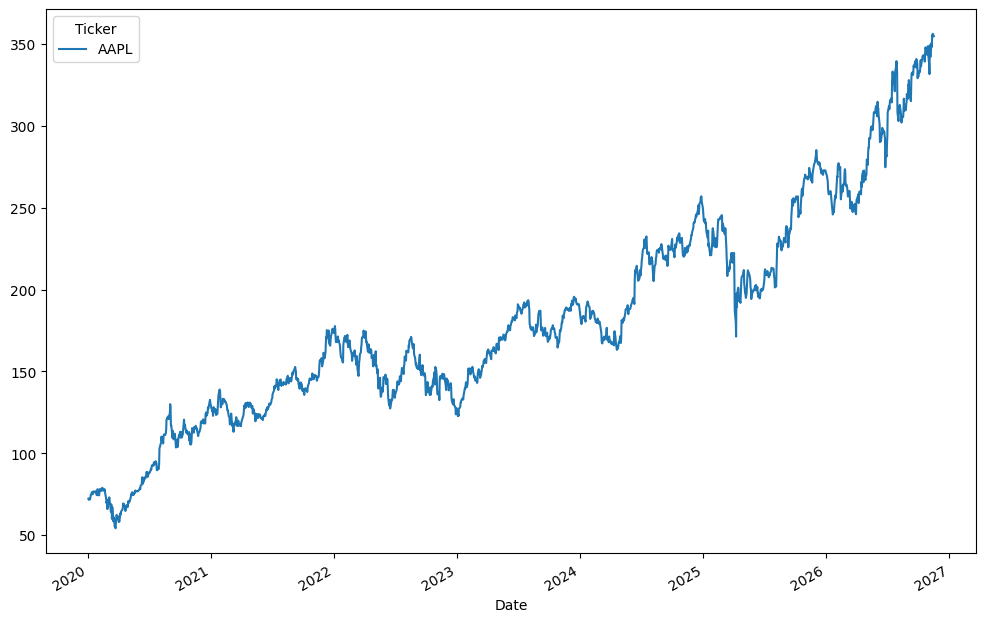

In [7]:
df.Close.plot(figsize=(12, 8))

In [8]:
scaler = StandardScaler()

df['Close'] = scaler.fit_transform(df[['Close']])

In [9]:
df.Close

Ticker,AAPL
Date,
2020-01-02,-1.675392
2020-01-03,-1.686178
2020-01-06,-1.677424
2020-01-07,-1.682632
2020-01-08,-1.664903
...,...
2026-11-10,2.564800
2026-11-11,2.674091
2026-11-12,2.666718


In [10]:
seq_length = 30
data = []

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])

data = np.array(data)

In [11]:
data

array([[[-1.67539225],
        [-1.68617754],
        [-1.67742412],
        ...,
        [-1.60145382],
        [-1.57335294],
        [-1.58197967]],

       [[-1.68617754],
        [-1.67742412],
        [-1.68263194],
        ...,
        [-1.57335294],
        [-1.58197967],
        [-1.58168304]],

       [[-1.67742412],
        [-1.68263194],
        [-1.66490312],
        ...,
        [-1.58197967],
        [-1.58168304],
        [-1.60371211]],

       ...,

       [[ 2.28558855],
        [ 2.33731708],
        [ 2.32503751],
        ...,
        [ 2.59826291],
        [ 2.56480044],
        [ 2.6740907 ]],

       [[ 2.33731708],
        [ 2.32503751],
        [ 2.33639637],
        ...,
        [ 2.56480044],
        [ 2.6740907 ],
        [ 2.66671752]],

       [[ 2.32503751],
        [ 2.33639637],
        [ 2.38305959],
        ...,
        [ 2.6740907 ],
        [ 2.66671752],
        [ 2.68806965]]], shape=(1698, 30, 1))

In [19]:
train_size = int(len(data) * 0.8)

X_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)
X_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)

In [13]:
class PredictionModel(nn.Module):
    def __init__(self, input_dim, hidden_size, num_layers, output_dim):
        super(PredictionModel, self).__init__()

        self.num_layers = num_layers
        self.hidden_size = hidden_size

        self.lstm = nn.LSTM(input_dim, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=device)

        out, (hn , cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])
        return out

In [14]:
model = PredictionModel(input_dim=1, hidden_size=32, num_layers=2, output_dim=1).to(device)

In [15]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [17]:
num_epochs = 200

for i in range(num_epochs):
    y_train_pred = model(X_train)

    loss = criterion(y_train_pred, y_train)

    if i % 25 == 0:
        print(i, loss)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    

0 tensor(0.0024, grad_fn=<MseLossBackward0>)
25 tensor(0.0022, grad_fn=<MseLossBackward0>)
50 tensor(0.0021, grad_fn=<MseLossBackward0>)
75 tensor(0.0020, grad_fn=<MseLossBackward0>)
100 tensor(0.0020, grad_fn=<MseLossBackward0>)
125 tensor(0.0020, grad_fn=<MseLossBackward0>)
150 tensor(0.0020, grad_fn=<MseLossBackward0>)
175 tensor(0.0020, grad_fn=<MseLossBackward0>)


In [20]:
model.eval()
y_test_pred = model(X_test)

y_train_pred = scaler.inverse_transform(y_train_pred.detach().cpu().numpy())
y_train = scaler.inverse_transform(y_train.detach().cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scaler.inverse_transform(y_test.detach().cpu().numpy())

In [21]:
train_rmse = root_mean_squared_error(y_train[:, 0], y_train_pred[:, 0])
test_rmse = root_mean_squared_error(y_test[:, 0], y_test_pred[:, 0])

In [22]:
train_rmse

2.8923468589782715

In [23]:
test_rmse

7.884955406188965

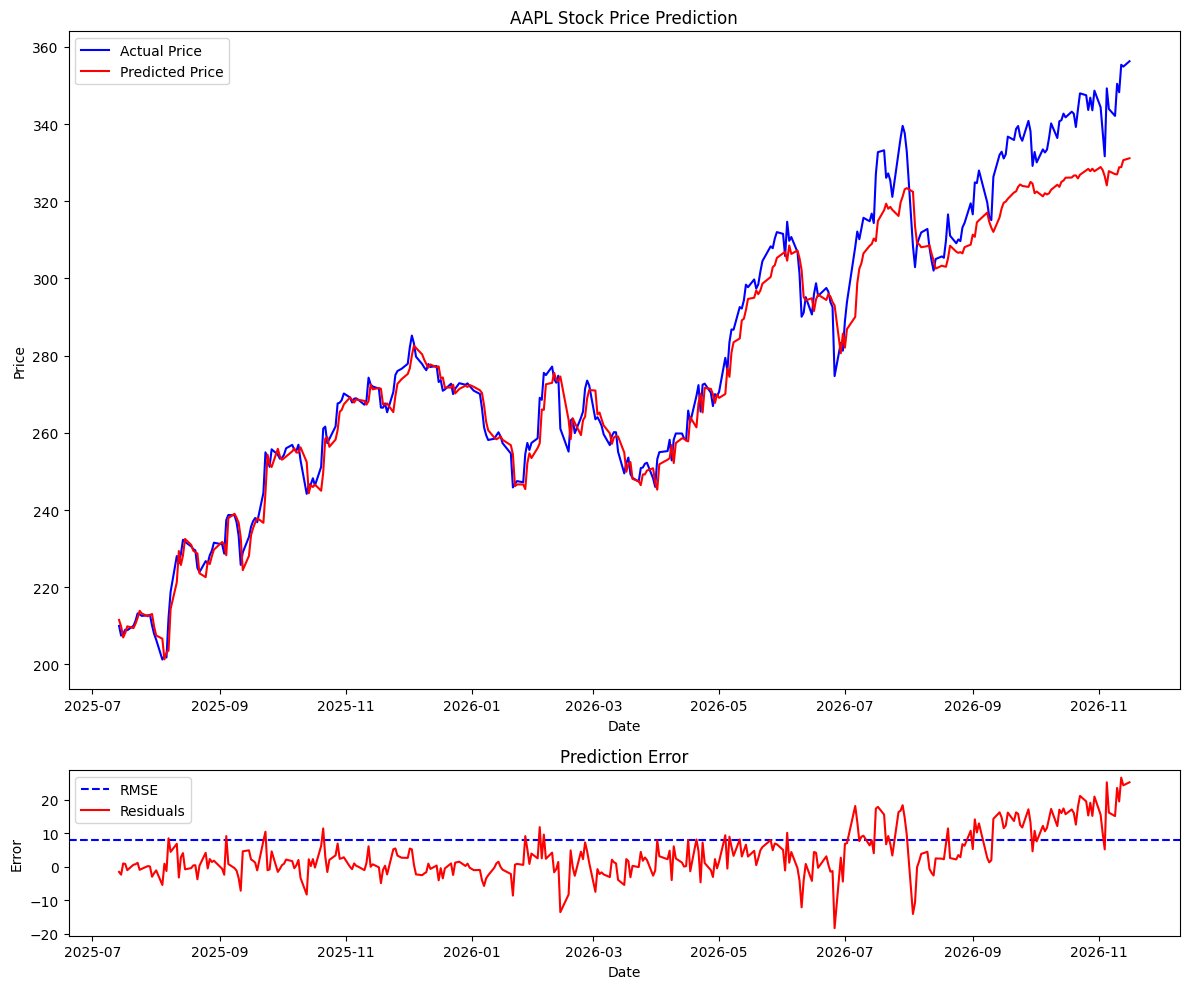

In [27]:
fig = plt.figure(figsize=(12, 10))

gs = fig.add_gridspec(4, 1)
axl = fig.add_subplot(gs[:3, 0])
axl.plot(df.iloc[-len(y_test):].index, y_test, color='blue', label='Actual Price')
axl.plot(df.iloc[-len(y_test):].index, y_test_pred, color='red', label='Predicted Price')
axl.legend()
plt.title(f"{ticker} Stock Price Prediction")
plt.xlabel('Date')
plt.ylabel('Price')

ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color='blue', linestyle='--', label='RMSE')
ax2.plot(df[-len(y_test):].index, y_test - y_test_pred, color='red', label='Residuals')
ax2.legend()
plt.title('Prediction Error')
plt.xlabel('Date')
plt.ylabel('Error')

plt.tight_layout()
plt.show()